# VIPER: predict equatorial vertical plasma drift for any quiet day

Set a date and run all cells. Behind the scenes VIPER:

1. checks OMNI daily max **Kp ≤ 3** (VIPER is trained on quiet days only; disturbed days are rejected),
2. downloads the 96 JPL GIM TEC maps for that day and converts them to apex MLAT / MLT,
3. fits the equatorial ionization anomaly (EIA) crests and adds F10.7 and SYM-H,
4. runs the neural network (model from [Hugging Face](https://huggingface.co/reddysachin/VIPER)) with 500 Monte-Carlo dropout samples.

Reddy et al. (2025), *Earth and Space Science*, 12(6), e2024EA004167.

In [11]:
DATE = "2010-06-20"  # any UT day with JPLD maps, YYYY-MM-DD
OUT = "output"       # where CSVs and the animation are saved

In [12]:
import os
import viper
from IPython.display import Image

os.makedirs(OUT, exist_ok=True)
features, pred = viper.run_day(DATE)  # raises DisturbedDayError if daily max Kp > 3
pred.describe().round(1)

,mlt,mlat,glon,vz_pred,error
count,2112.0,2112.0,2112.0,2112.0,2112.0
mean,11.5,0.0,15.0,6.2,9.5
std,6.9,3.2,103.1,25.0,0.8
min,0.0,-5.0,-142.5,-102.1,8.4
25%,5.8,-3.0,-63.8,-11.3,9.0
50%,11.5,0.0,15.0,5.2,9.3
75%,17.2,3.0,93.8,19.3,9.8
max,23.0,5.0,172.5,90.5,13.6


## Western-hemisphere sectors (as in paper Fig. 8)
Lines are the MC-dropout median over −5° to 5° MLAT; shading is MAD + 8.3 m/s global error.

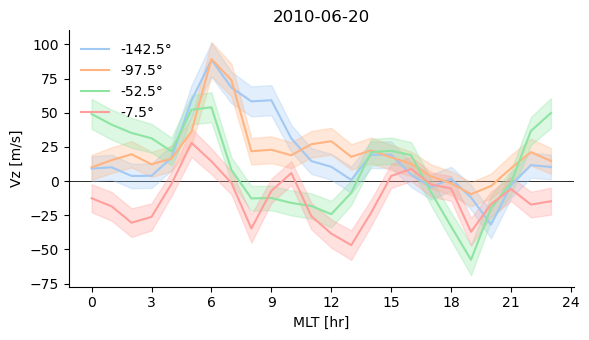

In [13]:
viper.plot_vz(pred, DATE);

## All eight longitude sectors

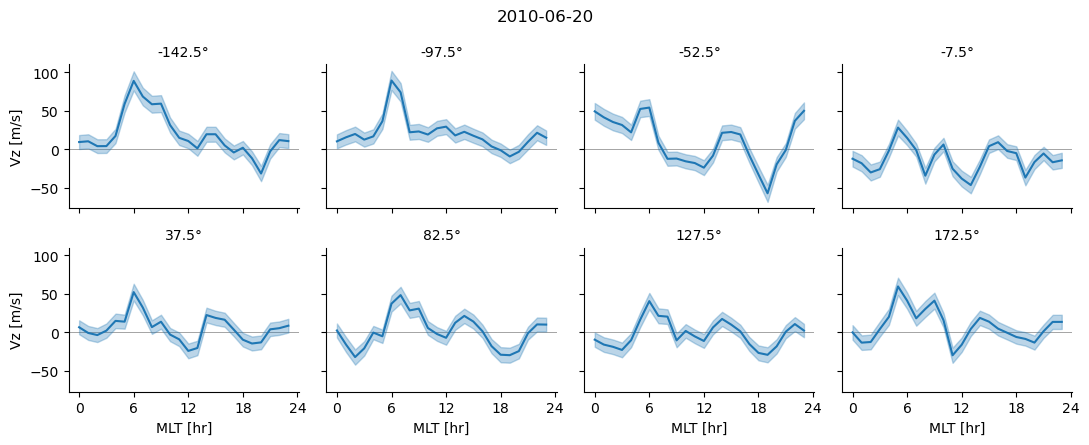

In [14]:
viper.plot_sectors(pred, DATE);

## MLT × longitude heatmap
Red is upward, blue downward. Look for the pre-reversal enhancement near 18–20 MLT. Blank cells are bins where the TEC grid or EIA fit had gaps.

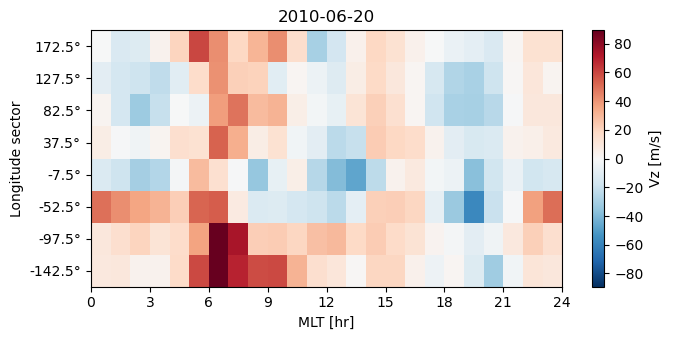

In [15]:
viper.plot_heatmap(pred, DATE);

## World map
Vz along the ±5° band around the magnetic equator at a chosen UT, with the night side shaded. Change `UT` to move through the day. Install `cartopy` for coastlines.

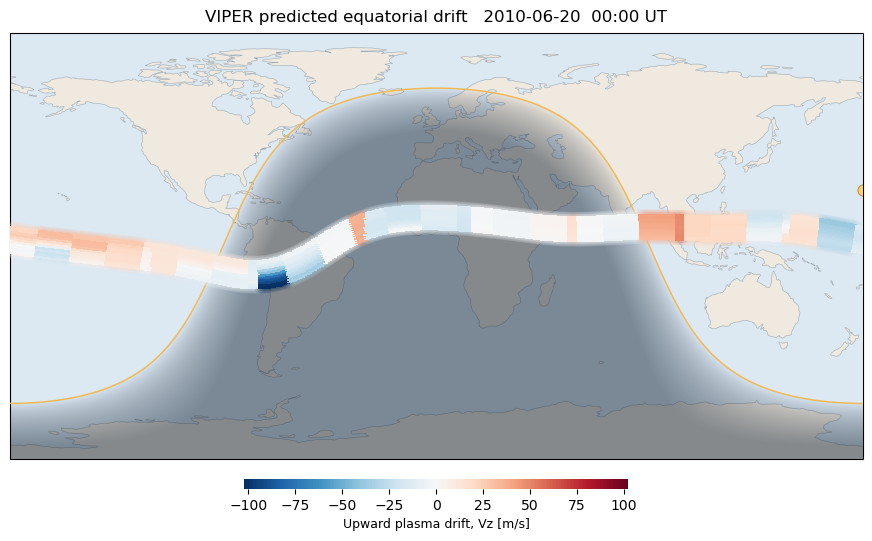

In [16]:
UT = 0  # hours
viper.plot_world(pred, DATE, ut=UT);

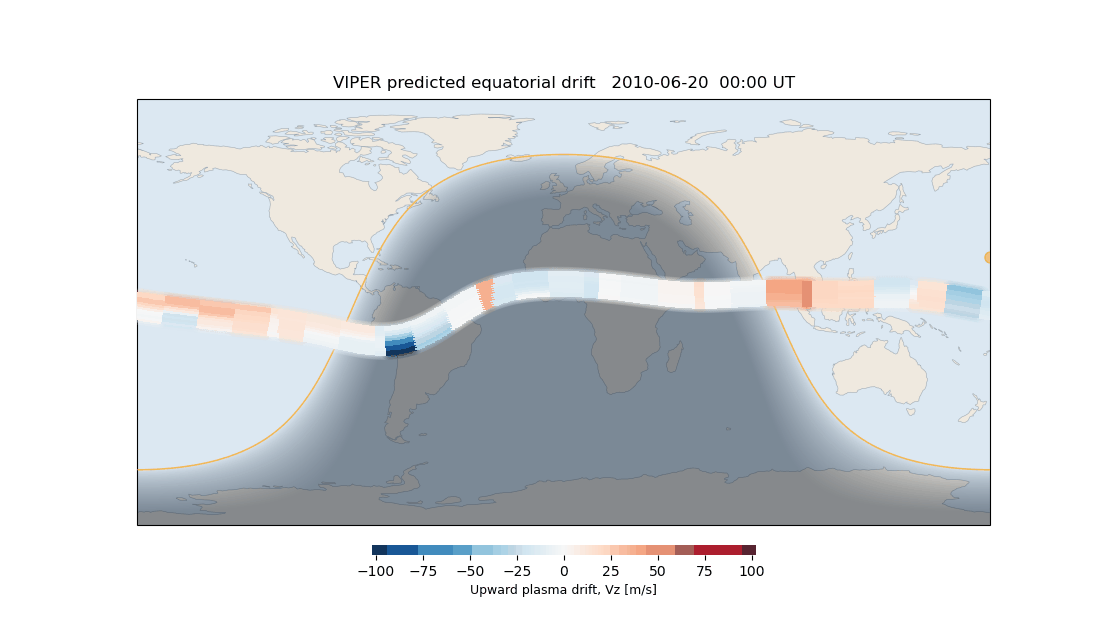

In [17]:
# animate through the UT day (~1 min)
viper.animate_world(pred, DATE, f"{OUT}/{DATE}_world.gif")
Image(f"{OUT}/{DATE}_world.gif")

## Save results

In [18]:
features.to_csv(f"{OUT}/{DATE}_features.csv", index=False)  # 21-column model input
pred.to_csv(f"{OUT}/{DATE}_vz.csv", index=False)            # mlt, mlat, glon, vz_pred, error